# BEE 4750 Homework 6: Linear Programs and Shadow Prices

**Name**: Anthony Santos

**ID**: acs367

> **Due Date**
>
> Thursday, 10/29/26, 9:00pm

## Overview

### Instructions

- Problem 1 asks you to formulate a water-supply problem as a linear
  program.
- Problem 2 asks you to interpret a linear program graphically.
- Problem 3 asks you to find the optimal solution to a stormwater plan
  and its shadow prices by hand, and to see where a shadow price stops
  being a good estimate.
- Problem 4 is a larger nutrient-management LP. The `JuMP` code that
  solves it is provided; you interpret its solution.
- Write your answers in Markdown cells. For the sketches, a photo or
  scan of a hand drawing is fine: save it in this folder and insert it
  with `![](sketch.png)`.

### Load Environment

In [1]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `c:\Users\thean\Downloads\BEE 4750\HW6\hw06`


In [2]:
using JuMP
using HiGHS
using Plots

## Problems (Total: 50 Points)

### Problem 1 (13)

A city of about 150,000 people supplies its drinking water from two
sources: a river intake and a groundwater well field. It must deliver at
least 20 million gallons per day (MGD). The operating cost (energy and
chemicals) of treating and pumping river water is \$300 per million
gallons; for groundwater, which has to be pumped from deeper, it is
\$500 per million gallons. The river withdrawal permit allows at most 15
MGD, and the well field can produce at most 12 MGD.

River water carries 8 mg/L of nitrate from farms upstream; the
groundwater carries 2 mg/L. To stay well below the 10 mg/L
drinking-water standard, the city requires the blended supply to average
at most 6 mg/L of nitrate. The city wants to meet demand at the lowest
daily cost.

#### Problem 1.1 (1)

Define the decision variables, with units.

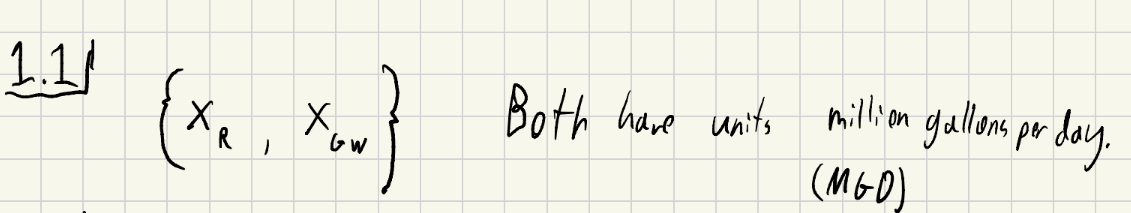

#### Problem 1.2 (2)

What are the bounds on each decision variable, and where does each bound
come from?

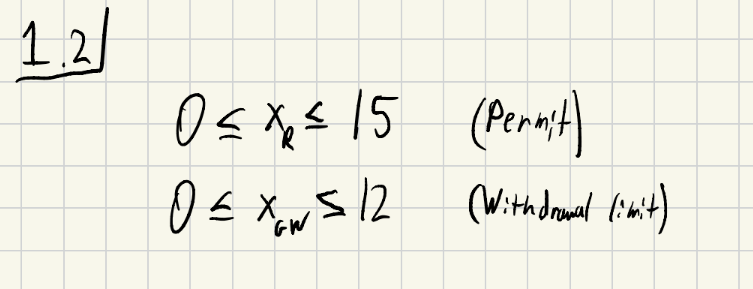


#### Problem 1.3 (2)

Write the objective function, with units. Is the city maximizing or
minimizing it?

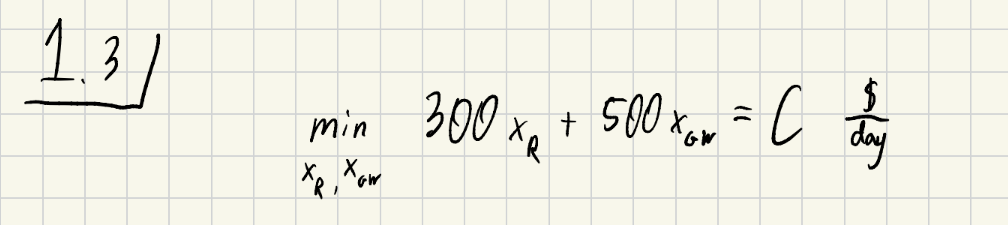

#### Problem 1.4 (5)

Write every constraint in linear form, including the bounds from Problem
1.2, each with a short label saying what it represents and with units
that agree on both sides.

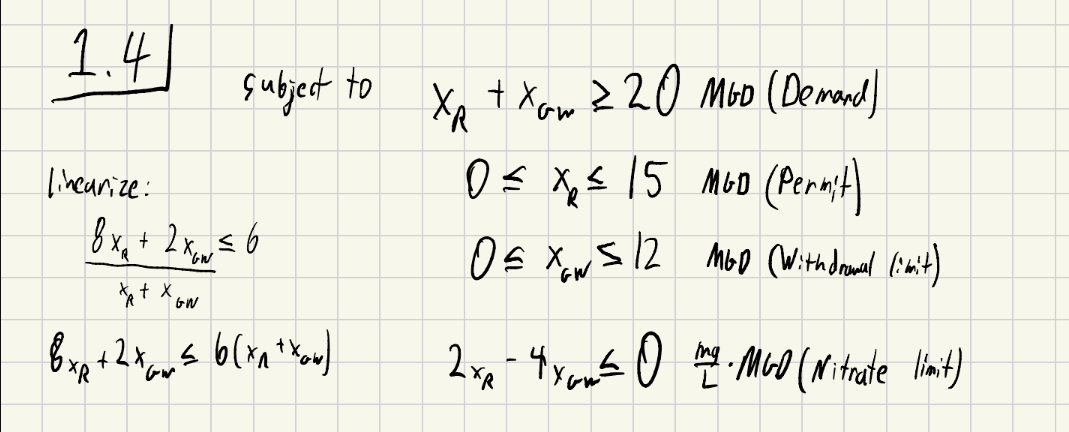

#### Problem 1.5 (3)

Write the problem in standard form,

$$\max_{\mathbf{x}} \quad \mathbf{c}^\top \mathbf{x} \qquad \text{subject to} \quad \mathbf{A}\mathbf{x} \leq \mathbf{b}, \quad \mathbf{x} \geq \mathbf{0},$$

where $\mathbf{x}$ is the vector of decision variables.
$\mathbf{A}\mathbf{x} \leq \mathbf{b}$ collects every constraint except
$\mathbf{x} \geq \mathbf{0}$: $\mathbf{A}$ has one row, and $\mathbf{b}$
one entry, for each. Give the vector $\mathbf{c}$, the matrix
$\mathbf{A}$, and the vector $\mathbf{b}$ explicitly.

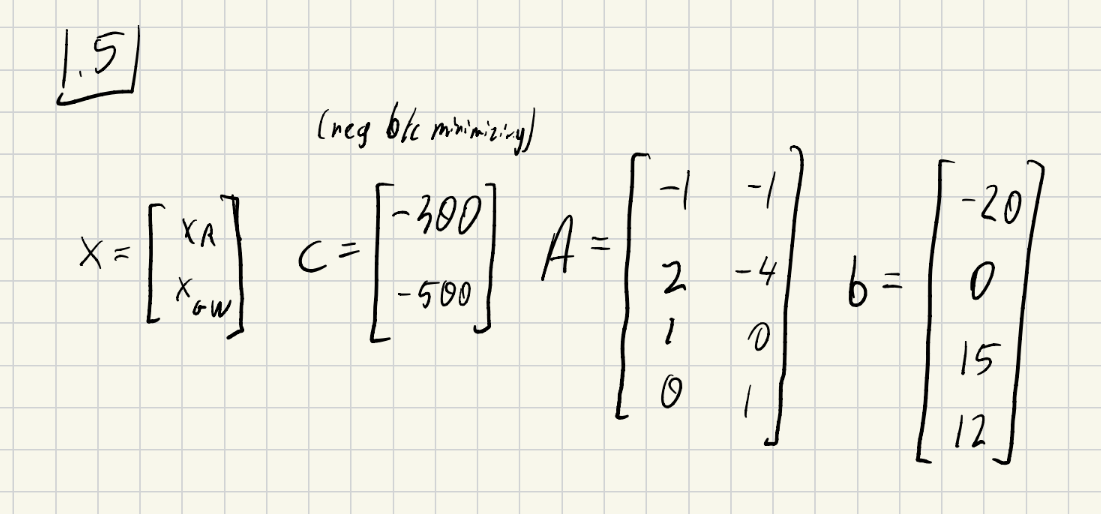

### Problem 2 (7)

Consider the linear program

$$\begin{aligned}
\max_{x_1, x_2} \quad & z = 3x_1 + 2x_2 \\
\text{subject to:} \quad & x_1 + x_2 \leq 8 \\
& 2x_1 + x_2 \leq 12 \\
& x_2 \leq 6 \\
& x_1, x_2 \geq 0.
\end{aligned}$$

#### Problem 2.1 (2)

Sketch the feasible region. Label each constraint’s boundary line, and
label every corner of the region with its coordinates.

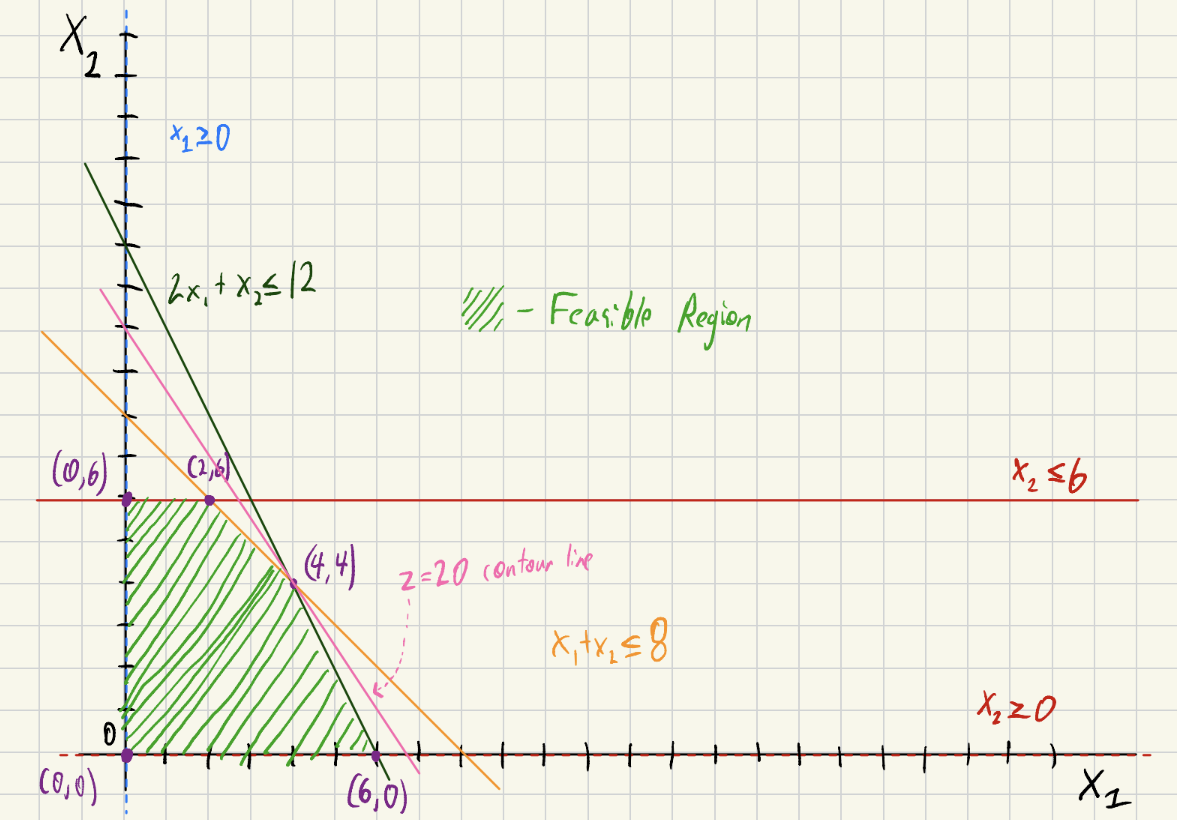


#### Problem 2.2 (5)

Say whether each of the following points is optimal for this linear
program, and justify each answer.

1.  $(4, 4)$
2.  $(2, 6)$
3.  $(3, 5)$
4.  $(2, 2)$
5.  $(5, 3)$

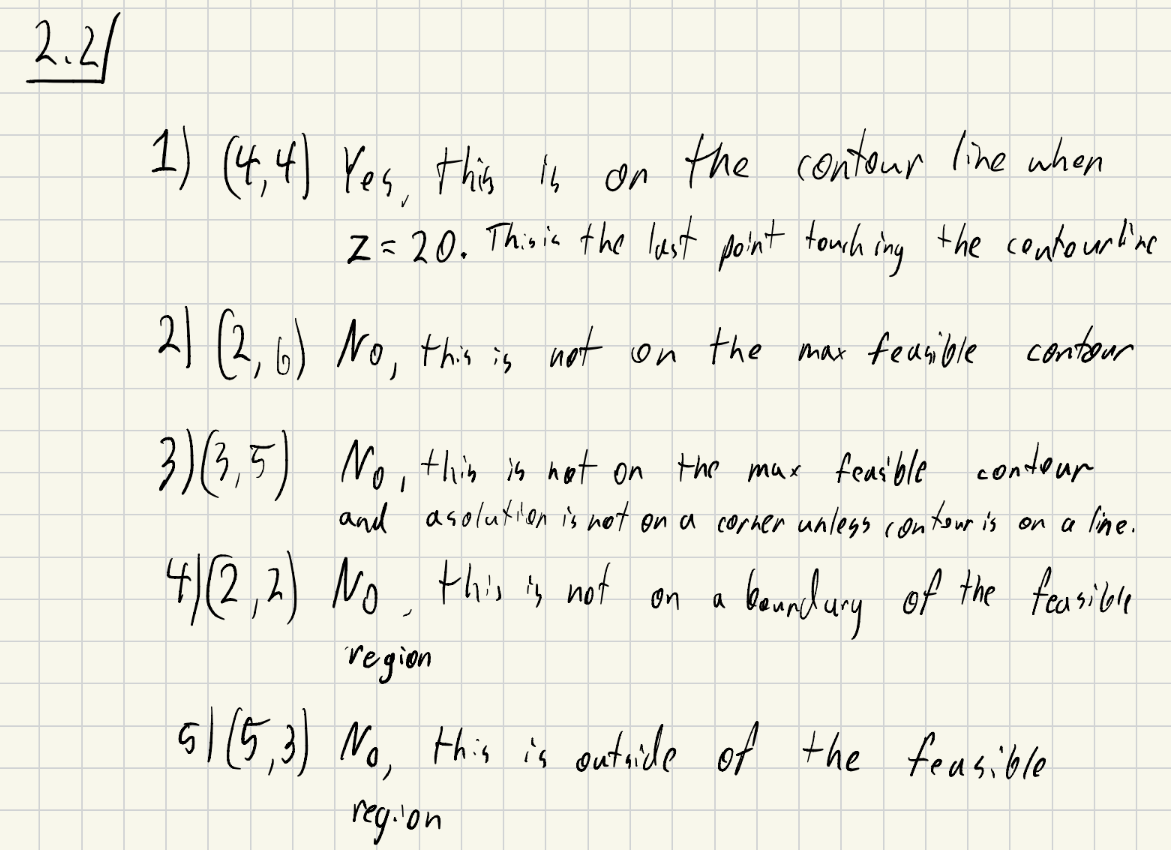

### Problem 3 (18)

A lakeside city is under a consent order to reduce the stormwater
reaching its combined sewers and the phosphorus reaching its lake. It
plans to build two kinds of green infrastructure in one sewershed:

- **Bioretention cells** (rain gardens): shallow planted basins that
  collect runoff from the surrounding pavement and roofs and filter it
  through soil. Each cell drains an area several times its own size.
- **Permeable pavement**: parking-lot surfaces that let rain soak
  through into a stone reservoir underneath. It mostly handles the rain
  that falls on it.

Per acre built, the two options have the following performance and cost
characteristics. The costs are annualized: construction spread over the
lifetime of the infrastructure plus maintenance.

| Per acre built                       | Bioretention | Permeable pavement |
|:-------------------------------------|-------------:|-------------------:|
| Runoff captured (million gallons/yr) |            5 |                  2 |
| Phosphorus removed (kg/yr)           |            5 |                  1 |
| Annualized cost (\$1,000/yr)         |           50 |                 30 |

The consent order requires the city to capture at least 40 million
gallons of runoff per year and to remove at least 30 kg of phosphorus
per year. Suitable sites exist for at most 6 acres of bioretention, and
there are 15 acres of parking lots that could take permeable pavement.
With $B$ the acres of bioretention and $P$ the acres of permeable
pavement, the city’s problem is

$$\begin{aligned}
\min_{B, P} \quad & 50B + 30P && (\$1\text{,}000/\text{yr}) \\
\text{subject to:} \quad & 5B + 2P \geq 40 && \text{runoff captured (million gal/yr)} \\
& 5B + P \geq 30 && \text{phosphorus removed (kg/yr)} \\
& B \leq 6 && \text{bioretention sites (acres)} \\
& P \leq 15 && \text{parking lots (acres)} \\
& B, P \geq 0.
\end{aligned}$$

#### Problem 3.1 (2)

Sketch the feasible region, with $B$ on the horizontal axis, and label
every corner with its coordinates.

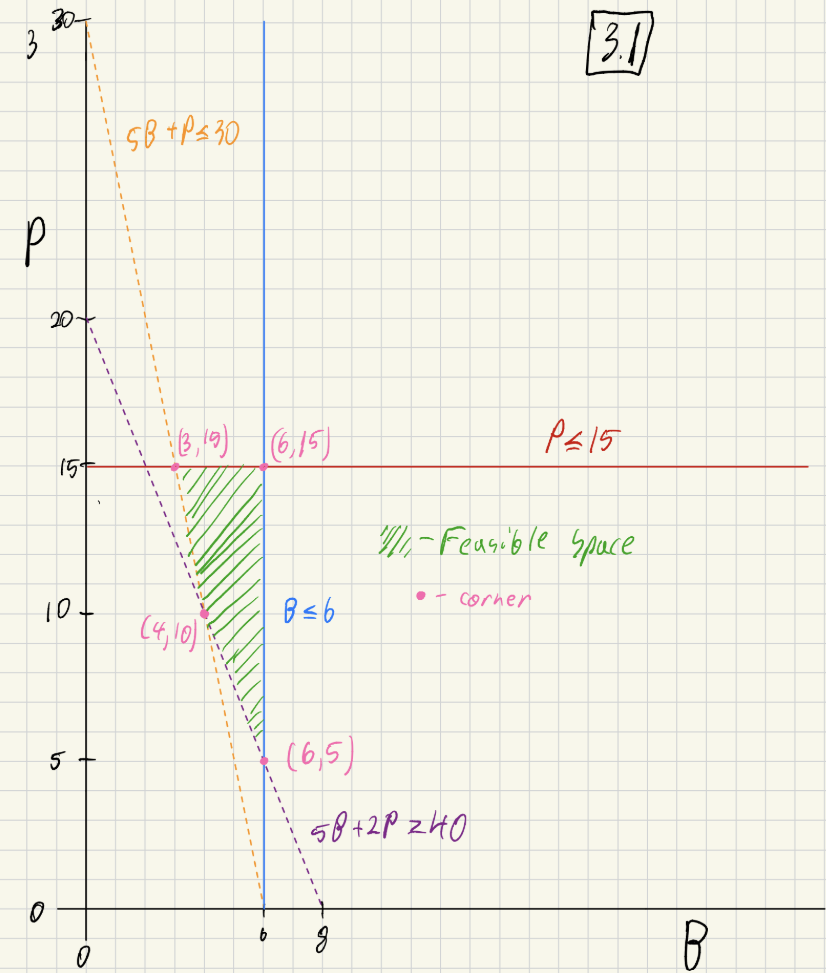

#### Problem 3.2 (2)

Find the optimal plan, using level lines of the cost or by evaluating
the cost at each corner, and report the minimum annual cost.

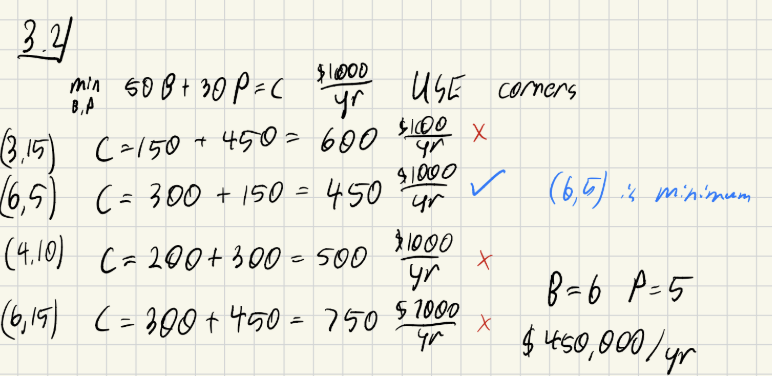

#### Problem 3.3 (1)

Which constraints are binding at the optimum?

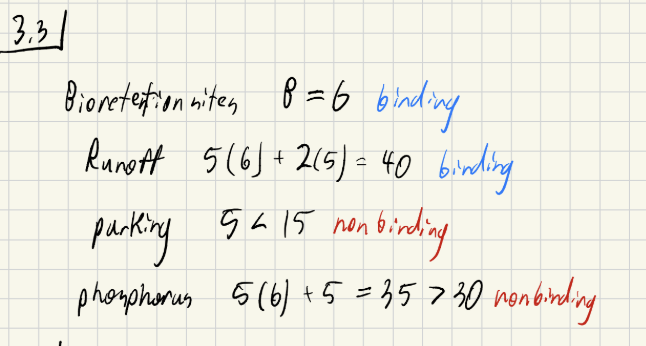


#### Problem 3.4 (4)

Find the shadow prices of the two binding constraints, with units. One
way: relax each binding constraint by one unit, find where the optimal
corner moves, and compute how much the cost falls. You can check your
answer with the method from lecture, writing the cost coefficients as a
combination of the binding constraints’ coefficients.

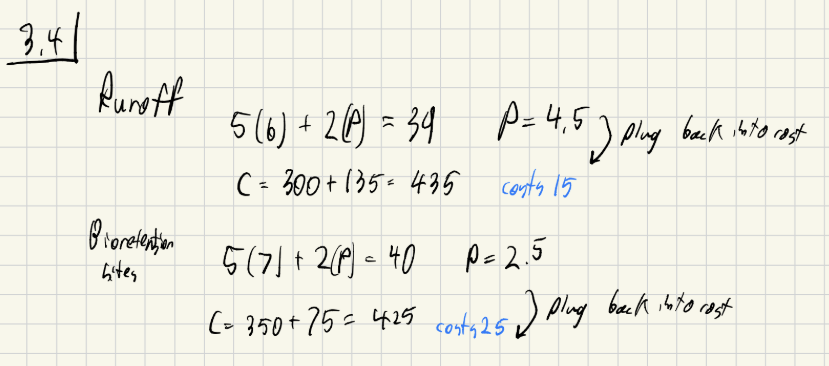


#### Problem 3.5 (1)

The shadow price of the phosphorus constraint is zero. What does that
mean for the city?

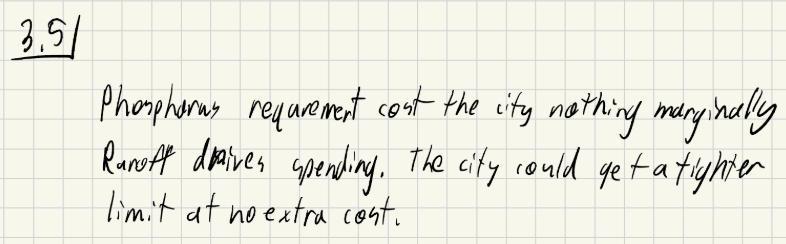

#### Problem 3.6 (2)

A school district offers a 4-acre site for bioretention, but only as a
single lease, at \$60,000 per year for the whole site. Using only the
shadow price of the bioretention-site constraint, estimate how much 4
more acres would save the city each year. On that estimate, should the
city sign the lease?

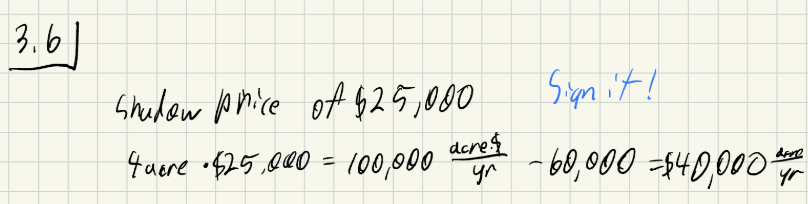

#### Problem 3.7 (3)

Raise the bioretention limit from 6 to 10 acres. Find the new optimal
plan and its annual cost by hand, by extending your sketch from Problem
3.1.

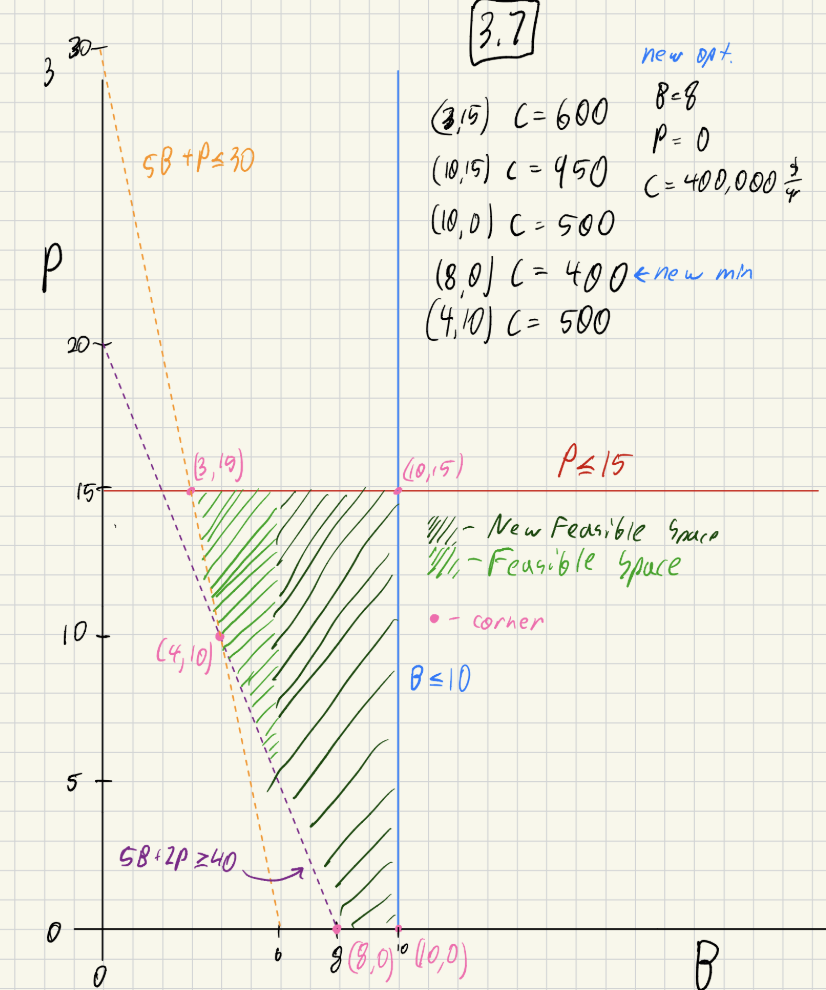


#### Problem 3.8 (1)

How much does the city actually save with the 10-acre limit, and should
it sign the lease?

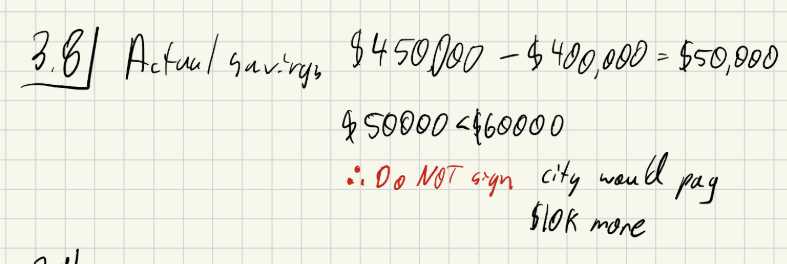


#### Problem 3.9 (2)

Look at your plan from Problem 3.7. Why is the shadow-price estimate
from Problem 3.6 wrong for a change this large?

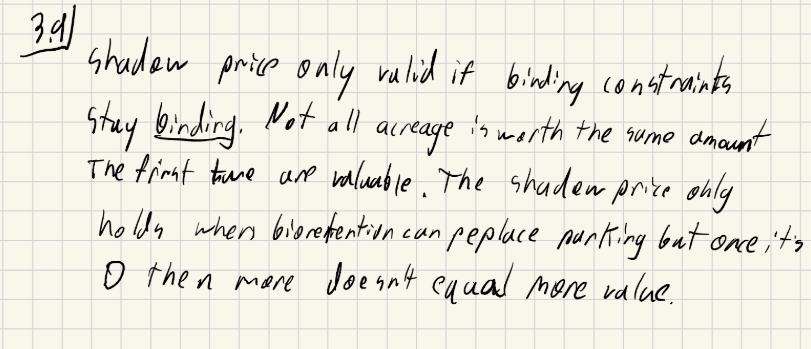


### Problem 4 (12)

Nitrogen from farms and wastewater treatment plants feeds algal blooms
in rivers, reservoirs and estuaries. A state agency is setting limits on
the nitrogen load reaching three points on a river: a drinking-water
**intake**, a **reservoir**, and the **estuary** at the river’s mouth.
Six sources release nitrogen to the river. Going downstream, the river
passes the upper farms and an upstream town’s treatment plant, then the
intake; then the middle farms and a city’s treatment plant, then the
reservoir; then the lower farms and a coastal town’s treatment plant,
and then it reaches the estuary.

Not all the nitrogen a source releases reaches each point downstream of
it: plants and algae take some up, bacteria return some to the air, and
the reservoir traps about half of what flows into it. A source’s
**delivery ratio** to a point is the fraction of its nitrogen that
reaches that point; it is 0 for a point upstream of the source. Each
source can cut its nitrogen, with cover crops and buffer strips on the
farms or upgrades at the treatment plants, up to a maximum and at a cost
per kg removed. Loads and removals are in kg of nitrogen per day:

| Source                | Load with no cuts | Maximum removal | Cost per kg removed |
|:----------------------|------------------:|----------------:|--------------------:|
| Upper farms           |             1,000 |             300 |              \$3.50 |
| Upstream town’s plant |               200 |             160 |                 \$5 |
| Middle farms          |             1,200 |             360 |                 \$4 |
| City’s plant          |             1,500 |           1,200 |                 \$8 |
| Lower farms           |               800 |             240 |                 \$6 |
| Coastal town’s plant  |               300 |             240 |                 \$7 |

| Delivery ratio        | Intake | Reservoir | Estuary |
|:----------------------|-------:|----------:|--------:|
| Upper farms           |    0.4 |       0.3 |    0.15 |
| Upstream town’s plant |    0.8 |       0.6 |     0.3 |
| Middle farms          |      0 |       0.6 |     0.3 |
| City’s plant          |      0 |       0.8 |     0.4 |
| Lower farms           |      0 |         0 |     0.6 |
| Coastal town’s plant  |      0 |         0 |     0.9 |

The limits are 500 kg/day at the intake, 1,500 kg/day at the reservoir
and 1,200 kg/day at the estuary. The agency wants the cheapest set of
cuts that meets all three.

With six decision variables, you can’t draw the feasible region, and it
has far too many corners to check by hand. The code below writes the
problem as a linear program in `JuMP` and solves it; you only need to
run it. The shadow prices then do the work the picture did in Problems 2
and 3: they explain why the optimal plan looks the way it does.

In [3]:
source_name = ["Upper farms", "Upstream town", "Middle farms",
    "City", "Lower farms", "Coastal town"]
nitrogen_load = [1000, 200, 1200, 1500, 800, 300]   # [kg/day] with no cuts
max_removal = [300, 160, 360, 1200, 240, 240]       # [kg/day]
removal_cost = [3.5, 5, 4, 8, 6, 7]                 # [$ per kg removed]

point_name = ["Intake", "Reservoir", "Estuary"]
load_limit = [500, 1500, 1200]                      # [kg/day]
# delivery[j, i]: the fraction of source i's nitrogen that reaches point j
delivery = [0.4  0.8  0    0    0    0;
            0.3  0.6  0.6  0.8  0    0;
            0.15 0.3  0.3  0.4  0.6  0.9]

n_sources = length(nitrogen_load)
n_points = length(load_limit)

nutrients = Model(HiGHS.Optimizer)
set_silent(nutrients)

# removal at each source [kg/day], up to its maximum
@variable(nutrients, 0 <= removal[i in 1:n_sources] <= max_removal[i])
# daily cost [$/day]
@objective(nutrients, Min,
    sum(removal_cost[i] * removal[i] for i in 1:n_sources))
# the nitrogen reaching each point [kg/day] stays within its limit
@constraint(nutrients, limit[j in 1:n_points],
    sum(delivery[j, i] * (nitrogen_load[i] - removal[i])
        for i in 1:n_sources) <= load_limit[j])

optimize!(nutrients)
println("Daily cost: \$", round(objective_value(nutrients); digits=2))

# How much each source removes [kg/day]. Adding 0 after rounding
# turns a -0.0 from the solver into 0
for i in 1:n_sources
    kg_removed = round(value(removal[i]); digits=1) + 0
    println(source_name[i], ": removes ", kg_removed, " of at most ",
        max_removal[i], " kg/day")
end

# The nitrogen reaching each point with the plan [kg/day], and the
# shadow price of the point's limit
reaching = zeros(n_points)
for j in 1:n_points
    for i in 1:n_sources
        kg_left = nitrogen_load[i] - value(removal[i])
        reaching[j] = reaching[j] + delivery[j, i] * kg_left
    end
    limit_price = round(shadow_price(limit[j]); digits=2) + 0
    println(point_name[j], ": ", round(reaching[j]; digits=1),
        " kg/day reaching, limit ", load_limit[j],
        " kg/day, shadow price ", limit_price)
end

Daily cost: $10040.0
Upper farms: removes 0.0 of at most 300 kg/day
Upstream town: removes 160.0 of at most 160 kg/day
Middle farms: removes 360.0 of at most 360 kg/day
City: removes 660.0 of at most 1200 kg/day
Lower farms: removes 140.0 of at most 240 kg/day
Coastal town: removes 240.0 of at most 240 kg/day
Intake: 432.0 kg/day reaching, limit 500 kg/day, shadow price 0.0
Reservoir: 1500.0 kg/day reaching, limit 1500 kg/day, shadow price -5.0
Estuary: 1200.0 kg/day reaching, limit 1200 kg/day, shadow price -10.0


#### Problem 4.1 (2)

Run the model. Report the daily cost, how much each source removes (as a
table), and the load reaching each of the three points, compared with
its limit.

The cheapest plan costs $10,040 per day.

| Source        | Removal (kg/day) | Maximum (kg/day) | Cost (\$/day) |
|:--------------|-----------------:|-----------------:|--------------:|
| Upper farms   |                0 |              300 |             0 |
| Upstream town |              160 |              160 |           800 |
| Middle farms  |              360 |              360 |         1,440 |
| City          |              660 |            1,200 |         5,280 |
| Lower farms   |              140 |              240 |           840 |
| Coastal town  |              240 |              240 |         1,680 |
| **Total**     |        **1,560** |                  |    **10,040** |

| Point     | Load reaching (kg/day) | Limit (kg/day) | Status                 |
|:----------|-----------------------:|---------------:|:-----------------------|
| Intake    |                    432 |            500 | 68 kg/day under limit  |
| Reservoir |                  1,500 |          1,500 | at limit (binding)     |
| Estuary   |                  1,200 |          1,200 | at limit (binding)     |

The reservoir and estuary limits are binding, while the intake limit is slack:
no cuts are made for the intake's sake. Three sources (upstream town, middle
farms, coastal town) remove their maximum, two (city, lower farms) remove
part of theirs, and the upper farms remove nothing.


#### Problem 4.2 (3)

Which limits bind? Report the shadow price of each limit, as a positive
number with units.

#### Problem 4.3 (4)

Write $d_{ji}$ for source $i$’s delivery ratio to point $j$ and $c_i$
for its cost per kg removed. Removing 1 more kg/day at source $i$ lowers
the load reaching each point $j$ by $d_{ji}$ kg/day. With $\lambda_j$
the shadow price of point $j$’s limit (as a positive number), that
kilogram is worth

$$v_i = \sum_{j} \lambda_j d_{ji} \qquad (\$ \text{ per kg removed}).$$

Compute $v_i$ for each source and compare it with the source’s cost,
$c_i$. Use the comparison to explain why each source removes nothing,
less than its maximum, or its maximum.






#### Problem 4.4 (3)

The upper farms are the cheapest source per kg removed, and the city’s
plant is the most expensive. Why does the plan cut nothing at the upper
farms, but more at the city’s plant than at any other source?